In [1]:
print('In the name of Allah')

In the name of Allah


# Multiple Linear Regression

This notebook is annotated with simple explanations. Code is unchanged.

## Visualization (EDA)
We visualize relationships between features and target variable.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

In [3]:
X = np.array([
    [1,4, 1.5, 3.8],
    [3,6, 1.0, 3.1],
    [4,7, 0.8, 3.9],
    [5,8, 0.4, 3.4],
    [7,9, 0.2, 2.8]
])

# W = [5, 10, -2, 0.5], b=2.0
y = np.array([ 45.9 ,  76.55,  92.35, 107.9 , 128.  ])

## Visualization (EDA)
We visualize relationships between features and target variable.

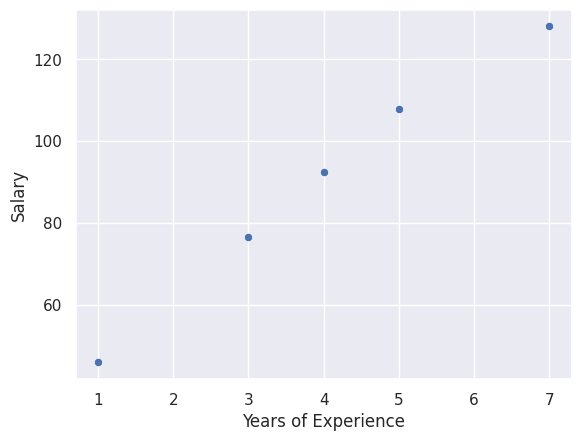

In [4]:
# Visualize the relationship between experience and salary

sns.scatterplot(x = X[:, 0:1].ravel(), y = y)

plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.show()

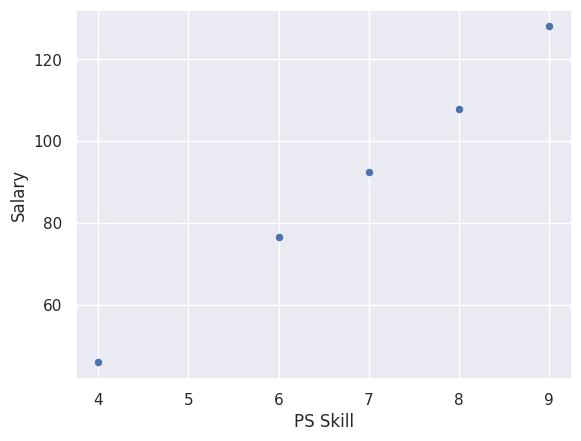

In [5]:
sns.scatterplot(x = X[:, 1:2].ravel(), y = y)

plt.xlabel('PS Skill')
plt.ylabel('Salary')
plt.show()

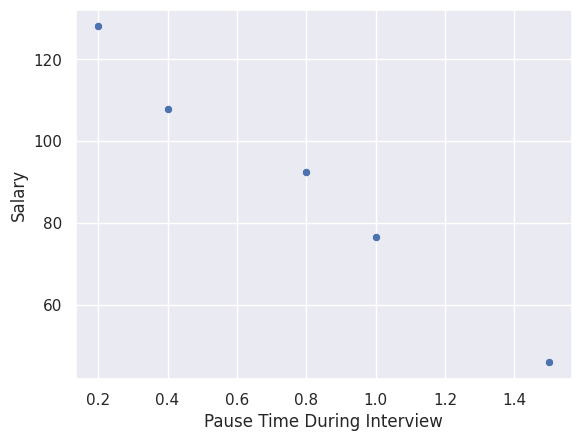

In [6]:
sns.scatterplot(x = X[:, 2:3].ravel(), y = y)

plt.xlabel('Pause Time During Interview')
plt.ylabel('Salary')
plt.show()

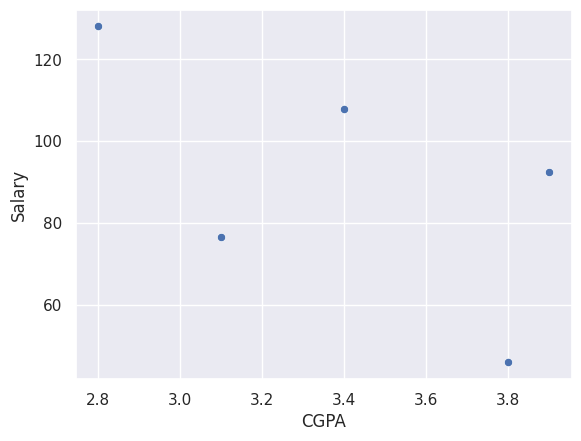

In [7]:
sns.scatterplot(x = X[:, 3:].ravel(), y = y)

plt.xlabel('CGPA')
plt.ylabel('Salary')
plt.show()

## Prediction Function
Computes y = w1x1 + w2x2 + ... + b

In [8]:
def make_prediction( X, W, b ) :

  """Calculates the model output : f(x) = wx + b"""

  m = X.shape[0]
  pred_list = np.zeros((m,))

  for i in range(m) :
    # X[i] = Feature Vector, W = weights_vector

    pred_list[i] = np.dot(W, X[i]) + b

  return pred_list


In [9]:
m = X.shape[0] # row
n = X.shape[1] # column

W_init = np.ones((n, ))
b_init = 1.0

make_prediction(X, W_init, b_init)

array([11.3, 14.1, 16.7, 17.8, 20. ])

## Cost Function
Measures error using Mean Squared Error (MSE).

In [10]:
# cost function

def compute_cost( X, y, W, b ) :

  """Calculates the Mean Squared Error (MSE) to measure model accuracy"""

  m = X.shape[0]
  cost = 0.0

  pred_list = make_prediction( X, W, b )

  # print(pred_list)

  error = pred_list - y
  # print(error)

  error_squared = error ** 2
  # print(error_squared)

  cost = np.sum(error_squared)

  # We divide by 2m for mathematical convenience in gradient calculations

  cost = cost / ( 2 * m )

  return cost


## Cost Function
Measures error using Mean Squared Error (MSE).

In [11]:
W_init = np.ones((n, ))
b_init = 1.0

compute_cost(X, y, W_init, b_init)

np.float64(3060.2095)

## Gradient Computation
Calculates partial derivatives for optimization.

In [12]:
# Gradient

def calculate_gradient( X, y, W, b ) :

  m = X.shape[0]
  n = X.shape[1]

  dj_dw = np.zeros((n,))
  dj_db = 0.0

  for i in range(m) :

    prediction = np.dot(W, X[i]) + b
    error = prediction - y[i]

    dj_db = dj_db +  error

    for j in range(n) :

      dj_dw[j] = dj_dw[j] + ( error * X[i, j] )

  return dj_dw / m, dj_db / m


In [13]:
W_init = np.ones((n, ))
b_init = 1.0

calculate_gradient(X, y, W_init, b_init)

(array([-346.21 , -547.09 ,  -46.502, -245.77 ]), np.float64(-74.16))

## Gradient Descent
Updates weights iteratively to minimize cost.

In [14]:
def gradient_descent( X, y, w_input, b_input, max_iter, alpha = 0.01 ) : # Best value of alpha

  """Automates the tuning of w and b to minimize cost"""

  w = w_input
  b = b_input

  cost_memo = []
  iteration = []

  for i in range(max_iter) :
    # 1. Calculate the gradients (the slope)

    dj_dw, dj_db = calculate_gradient(X, y, w, b)

    # 2. Update parameters by taking a small step (alpha) against the gradient

    w = w - alpha * dj_dw
    b = b - alpha * dj_db


    # 3. Track progress by saving the cost

    cost = compute_cost( X, y, w, b )
    cost_memo.append( cost )
    iteration.append(i)

    # Log the status every 1000 steps
    if i % 1000 == 0 :
      print( f'Iteration : {i}, w : {w}, b : {b:0.4f}, dj_dw : {dj_dw}, dj_db : {dj_db}, cost : {cost:0.4f}' )

  return w, b, cost_memo, iteration

In [15]:
W_init = np.zeros((n,))
b_init = 0.0

w_final, b_final, cost_memo, iter_list = gradient_descent( X, y, w_input = W_init, b_input = b_init, max_iter = 450001, alpha = 0.01 )

Iteration : 0, w : [4.1609  6.6091  0.57608 2.9943 ], b : 0.9014, dj_dw : [-416.09  -660.91   -57.608 -299.43 ], dj_db : -90.14, cost : 188.4458
Iteration : 1000, w : [ 6.50691618  8.72699884 -0.67166594  1.35987549], b : 0.6700, dj_dw : [ 0.04327378 -0.04096339  0.02068675  0.02600783], dj_db : 0.0009087181364535013, cost : 0.0830
Iteration : 2000, w : [ 6.12978184  9.08367849 -0.85398761  1.13443372], b : 0.6617, dj_dw : [ 0.03266107 -0.03085889  0.01598453  0.01940813], dj_db : 0.000755908320995502, cost : 0.0474
Iteration : 3000, w : [ 5.84513045  9.3523715  -0.99487745  0.96621059], b : 0.6548, dj_dw : [ 0.02465245 -0.02324606  0.01235344  0.01448115], dj_db : 0.0006063054368567577, cost : 0.0271
Iteration : 4000, w : [ 5.63027141  9.55477258 -1.1037784   0.84070168], b : 0.6495, dj_dw : [ 0.01860851 -0.01751013  0.00955041  0.01080332], dj_db : 0.00046742868826470384, cost : 0.0156
Iteration : 5000, w : [ 5.46808501  9.70722425 -1.18798912  0.74707598], b : 0.6455, dj_dw : [ 0.01

In [16]:
print(w_final)
print(b_final)

# W = [5, 10, -2, 0.5], b = 2.0

[ 4.98752184 10.06761875 -1.79411751  0.48933694]
1.4656568397451641


## Making Predictions
Now that we have trained weights, we can predict the salary for a new person given their features.

## Prediction Function
Computes y = w1x1 + w2x2 + ... + b

In [17]:
X_test = [2,10, 1.5, 3.8]

prediction_of_new_data = w_final[0] * X_test[0] + w_final[1] * X_test[1] + w_final[2] * X_test[2] + w_final[3] * X_test[3] + b_final

print(prediction_of_new_data)

111.28519208489328


# Linear Regression using scikit learn

Using libraries like `scikit-learn` is the industry standard. It's much faster and handles the math automatically.

In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import SGDRegressor

In [19]:
model1 = LinearRegression()

model1.fit(X, y)

weights = model1.coef_
bias = model1.intercept_

print(weights)
print(bias)

[ 5.  10.  -2.   0.5]
2.000000000000142


The `SGDRegressor` implements Stochastic Gradient Descent. It's particularly useful for very large datasets where the standard `LinearRegression` might be too slow.

## SGDRegressor (Sklearn)
Built-in stochastic gradient descent implementation.

In [20]:
model2 = SGDRegressor(penalty = None, max_iter = 450001, learning_rate = 'constant')

model2.fit(X, y)

weights = model2.coef_
bias = model2.intercept_

print(weights)
print(bias)

[ 5.80142336  9.35027003 -0.87421824  0.87562841]
[0.7090411]
